<a href="https://colab.research.google.com/github/idamato/birdgarden/blob/main/custom_mobilenet_birdgarden_fixed_dependencies.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Birdgarden — addestramento MobileNetV2 per Raspberry Pi AI Camera

Questa versione aggiornata del notebook del progetto Birdgarden addestra un **classificatore di immagini a cinque classi (o al numero di classi presente nel dataset)**, applica la quantizzazione post-training prevista per Sony IMX500 e converte il modello con `imxconv-tf`.

## Struttura attesa del dataset

```text
Birdgarden/
├── train/
│   ├── SPECIE_1/ immagini...
│   └── SPECIE_2/ immagini...
├── valid/
│   ├── SPECIE_1/ immagini...
│   └── SPECIE_2/ immagini...
└── test/
    ├── SPECIE_1/ immagini...
    └── SPECIE_2/ immagini...
```

I nomi reali delle cartelle diventano le etichette del modello. Le cartelle di classe devono avere gli stessi nomi in tutti e tre gli split.

## Ambiente e uso

Il flusso è predisposto per Python 3.11 e per le versioni dei pacchetti coerenti con l'esecuzione salvata del notebook originale. Può essere usato in Google Colab; fuori da Colab, installare le dipendenze in un ambiente Linux compatibile e impostare il percorso del dataset nella cella **Configurazione**. La conversione IMX500 richiede il convertitore Sony e Java 17.

Eseguire le celle nell'ordine. Le celle di installazione e conversione richiedono Internet e possono richiedere tempo.

> **Limite progettuale:** questo è un classificatore, non un rilevatore. Per localizzare e ritagliare un uccello da una scena (ad esempio un uccello fotografato in una scena più ampia) serve prima un passaggio distinto di localizzazione/detection.


## 1. Verifica dell'ambiente

In [3]:
import sys
import os
import platform
import importlib.util

print("Python:", sys.version)
print("Sistema:", platform.platform())
IN_COLAB = importlib.util.find_spec("google.colab") is not None
print("Esecuzione in Google Colab:", IN_COLAB)

if sys.version_info[:2] != (3, 11):
    raise RuntimeError(
        "Questo notebook è configurato per Python 3.11. "
        "Usa un runtime Python 3.11 compatibile prima di proseguire."
    )

Python: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]
Sistema: Linux-6.6.122+-x86_64-with-glibc2.35
Esecuzione in Google Colab: True


## 2. Installazione delle dipendenze

Le versioni sono fissate per mantenere compatibile la pipeline Sony/Raspberry Pi AI Camera: TensorFlow 2.14.1, MCT 2.2.2 e IMX500 Converter 3.16.1. TensorFlow 2.14.1 richiede NumPy < 2 e `ml-dtypes==0.2.0`; per questo notebook blocchiamo esplicitamente `numpy==1.26.4` e `ml-dtypes==0.2.0`.

**Importante in Google Colab:** dopo un'installazione o un downgrade delle librerie, riavvia il runtime da *Runtime (Ambiente di esecuzione) → Restart session (Riavvia sessione)*. Il runtime può avere già caricato in memoria una versione diversa di NumPy: continuare senza riavvio può produrre errori in `ml_dtypes` o durante `import tensorflow`. La cella di installazione seguente si interrompe intenzionalmente quando cambia l'ambiente, così non si prosegue accidentalmente con moduli non coerenti.

Il convertitore IMX500 3.16.1 dichiara compatibilità con TensorFlow 2.12–2.15 e Python 3.8–3.11. Prima di cambiare queste versioni, verificare la [documentazione Sony IMX500 Converter](https://developer.aitrios.sony-semicon.com/docs/raspberry-pi-ai-camera/imx500-converter?version=3.16.1).

In [2]:
# Eseguire una volta per ogni ambiente nuovo. Le versioni principali sono intenzionalmente bloccate.
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError

CORE_VERSIONS = {
    'numpy': '1.26.4',
    'ml-dtypes': '0.2.0',
    'tensorflow': '2.14.1',
    'model-compression-toolkit': '2.2.2',
    'imx500-converter': '3.16.1',
}
OPTIONAL_DISTRIBUTIONS = ['scikit-learn', 'matplotlib']

def installed_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return None

mismatches = {name: (installed_version(name), required)
              for name, required in CORE_VERSIONS.items()
              if installed_version(name) != required}
missing_optional = [name for name in OPTIONAL_DISTRIBUTIONS
                    if installed_version(name) is None]

if mismatches or missing_optional:
    packages = [
        'numpy==1.26.4',
        'ml-dtypes==0.2.0',
        'tensorflow==2.14.1',
        'model-compression-toolkit==2.2.2',
        'imx500-converter[tf]==3.16.1',
        'scikit-learn',
        'matplotlib',
    ]
    print('Versioni da correggere/installare:', mismatches)
    print('Pacchetti opzionali mancanti:', missing_optional)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *packages])
    print('Installazione completata. RIAVVIA ORA il runtime prima di proseguire: Runtime/Ambiente di esecuzione → Restart session/Riavvia sessione. Poi riesegui il notebook dall’inizio.')
    raise RuntimeError('Ambiente aggiornato: riavvia il runtime e riesegui il notebook. Non continuare con le celle successive in questa sessione.')
else:
    print('Dipendenze principali già allineate:')
    for name in CORE_VERSIONS:
        print(f'  {name}: {installed_version(name)}')
    print('Puoi proseguire. Se hai appena installato/downgradato librerie in questa sessione, riavvia comunque il runtime prima di continuare.')


Versioni da correggere/installare: {'numpy': ('2.0.2', '1.26.4'), 'ml-dtypes': ('0.4.1', '0.2.0'), 'tensorflow': ('2.18.0', '2.14.1'), 'model-compression-toolkit': (None, '2.2.2'), 'imx500-converter': (None, '3.16.1')}
Pacchetti opzionali mancanti: []
Installazione completata. RIAVVIA ORA il runtime prima di proseguire: Runtime/Ambiente di esecuzione → Restart session/Riavvia sessione. Poi riesegui il notebook dall’inizio.


RuntimeError: Ambiente aggiornato: riavvia il runtime e riesegui il notebook. Non continuare con le celle successive in questa sessione.

## 3. Verifica di Java 17

In [1]:
import re
import shutil
import subprocess


def java_major_version():
    java_executable = shutil.which("java")
    if java_executable is None:
        return None
    result = subprocess.run(
        [java_executable, "-version"],
        capture_output=True,
        text=True,
        check=False,
    )
    text_output = result.stderr + result.stdout
    match = re.search(r'version "(?:1\.)?(\d+)', text_output)
    return int(match.group(1)) if match else None


java_version = java_major_version()
if java_version != 17:
    print(f"Java 17 non rilevato (versione rilevata: {java_version}).")
    if shutil.which("apt-get") is None:
        raise RuntimeError(
            "Serve Java 17 e apt-get non è disponibile. Installa Java 17 manualmente "
            "nell'ambiente Linux prima di eseguire la conversione IMX500."
        )
    subprocess.run(["apt-get", "update"], check=True)
    subprocess.run(["apt-get", "install", "-y", "openjdk-17-jdk"], check=True)
    java_version = java_major_version()

if java_version != 17:
    raise RuntimeError(f"È richiesto Java 17, ma la versione rilevata è {java_version}.")
print("Java 17 disponibile.")

Java 17 non rilevato (versione rilevata: 11).
Java 17 disponibile.


## 4. Import e configurazione

Per tracciare revisioni diverse del dataset, modificare la riga `DATASET_VERSION` in questa cella (per esempio `2026-10-v1`); il valore viene registrato nei metadati. La cartella del dataset si può cambiare tramite `BIRDGARDEN_DATASET` oppure modificando `DATASET_ROOT`.

In [4]:
import json
import os
import shutil
import random
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# Controllo preventivo prima di importare NumPy/TensorFlow: intercetta versioni
# incompatibili installate su disco o moduli vecchi ancora caricati in memoria.
EXPECTED_CORE_VERSIONS = {
    "numpy": "1.26.4",
    "ml-dtypes": "0.2.0",
    "tensorflow": "2.14.1",
    "model-compression-toolkit": "2.2.2",
    "imx500-converter": "3.16.1",
}

def _distribution_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"

wrong_versions = {
    name: (_distribution_version(name), expected)
    for name, expected in EXPECTED_CORE_VERSIONS.items()
    if _distribution_version(name) != expected
}
if wrong_versions:
    raise RuntimeError(
        "Le dipendenze non sono allineate: " + repr(wrong_versions) +
        ". Esegui la cella 'Installazione delle dipendenze', riavvia il runtime e riparti dall'inizio."
    )

# In Colab NumPy può essere stato importato prima di cambiare la versione installata.
for module_name, distribution_name in [("numpy", "numpy"), ("ml_dtypes", "ml-dtypes"), ("tensorflow", "tensorflow")]:
    loaded_module = sys.modules.get(module_name)
    loaded_version = getattr(loaded_module, "__version__", None) if loaded_module else None
    disk_version = _distribution_version(distribution_name)
    if loaded_version and loaded_version != disk_version:
        raise RuntimeError(
            f"Il modulo {module_name} caricato in memoria è {loaded_version}, ma su disco è installato {disk_version}. "
            "Riavvia il runtime (Runtime/Ambiente di esecuzione → Restart session/Riavvia sessione) e riesegui tutte le celle."
        )

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Google Drive viene montato solo quando si esegue in Colab.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/mnt/drive")
    DEFAULT_DATASET_PATH = Path("/mnt/drive/MyDrive/Birdgarden")
else:
    # Fuori da Colab, usare ./Birdgarden oppure impostare la variabile d'ambiente BIRDGARDEN_DATASET.
    DEFAULT_DATASET_PATH = Path("Birdgarden")

DATASET_ROOT = Path(os.environ.get("BIRDGARDEN_DATASET", str(DEFAULT_DATASET_PATH))).expanduser().resolve()
DATASET_VERSION = os.environ.get("BIRDGARDEN_DATASET_VERSION", "unspecified")

MODELS_DIR = Path("models") / "birdgarden"
CONVERTED_DIR = Path("converted") / "birdgarden"
DRIVE_OUTPUT_DIR = DATASET_ROOT / "artifacts"

TRAIN_DIR = DATASET_ROOT / "train"
VALID_DIR = DATASET_ROOT / "valid"
TEST_DIR = DATASET_ROOT / "test"

BATCH_SIZE = 32
IMAGE_SHAPE = (224, 224)
EPOCHS = 20
NUM_CALIBRATION_BATCHES = 10
NUM_PREVIEW_IMAGES = 6
LOW_CONFIDENCE_THRESHOLD = 0.55
PERSIST_TO_DRIVE = IN_COLAB

MODELS_DIR.mkdir(parents=True, exist_ok=True)
CONVERTED_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FLOAT = MODELS_DIR / "mobilenetv2_birdgarden.keras"
MODEL_QUANTIZED = MODELS_DIR / "mobilenetv2_birdgarden_quant.keras"
CLASS_NAMES_FILE = MODELS_DIR / "class_names.json"
DATASET_METADATA_FILE = MODELS_DIR / "dataset_metadata.json"
TRAINING_CONFIG_FILE = MODELS_DIR / "training_config.json"
TEST_METRICS_FILE = MODELS_DIR / "test_metrics.json"

print("Dataset:", DATASET_ROOT)
print("Directory modelli:", MODELS_DIR.resolve())
print("Directory conversione:", CONVERTED_DIR.resolve())
def get_package_version(distribution_name):
    try:
        return version(distribution_name)
    except PackageNotFoundError:
        return "not installed"


PACKAGE_VERSIONS = {
    "tensorflow": tf.__version__,
    "model-compression-toolkit": get_package_version("model-compression-toolkit"),
    "imx500-converter": get_package_version("imx500-converter"),
    "scikit-learn": get_package_version("scikit-learn"),
    "matplotlib": get_package_version("matplotlib"),
}
print("Versioni pacchetti:", PACKAGE_VERSIONS)


def persist_artifacts_to_drive():
    """Copia su Drive gli artefatti già creati, se si sta eseguendo in Colab."""
    if not PERSIST_TO_DRIVE:
        return
    if not DATASET_ROOT.is_dir():
        print("Dataset root non disponibile: impossibile copiare gli artefatti su Drive.")
        return
    DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    if MODELS_DIR.exists():
        destination_models = DRIVE_OUTPUT_DIR / "models"
        shutil.copytree(MODELS_DIR, destination_models, dirs_exist_ok=True)
        print("Modelli copiati/aggiornati su Drive:", destination_models)
    if CONVERTED_DIR.exists() and any(CONVERTED_DIR.iterdir()):
        destination_converted = DRIVE_OUTPUT_DIR / "converted"
        shutil.copytree(CONVERTED_DIR, destination_converted, dirs_exist_ok=True)
        print("Artefatti di conversione copiati/aggiornati su Drive:", destination_converted)


Mounted at /mnt/drive
Dataset: /mnt/drive/MyDrive/Birdgarden
Directory modelli: /content/models/birdgarden
Directory conversione: /content/converted/birdgarden
Versioni pacchetti: {'tensorflow': '2.14.1', 'model-compression-toolkit': '2.2.2', 'imx500-converter': '3.16.1', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}


## 5. Controllo della struttura del dataset

In [5]:
SUPPORTED_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}


def class_directories(split_path):
    """Restituisce i nomi delle sottocartelle di classe, in ordine alfabetico."""
    return sorted(p.name for p in split_path.iterdir() if p.is_dir())


def image_counts_by_class(split_path, class_names):
    """Conta i file immagine supportati presenti in ciascuna cartella di classe."""
    counts = {}
    for class_name in class_names:
        class_path = split_path / class_name
        counts[class_name] = sum(
            1 for p in class_path.rglob("*")
            if p.is_file() and p.suffix.lower() in SUPPORTED_IMAGE_EXTENSIONS
        ) if class_path.exists() else 0
    return counts


for split_name, split_path in [("train", TRAIN_DIR), ("valid", VALID_DIR), ("test", TEST_DIR)]:
    if not split_path.is_dir():
        raise FileNotFoundError(
            f"Cartella '{split_name}' non trovata: {split_path}\n"
            "Verifica DATASET_ROOT e che esistano train/, valid/ e test/."
        )
    if not class_directories(split_path):
        raise ValueError(f"Nessuna sottocartella di classe trovata in {split_path}")

train_folder_classes = class_directories(TRAIN_DIR)
for split_name, split_path in [("valid", VALID_DIR), ("test", TEST_DIR)]:
    split_classes = class_directories(split_path)
    if split_classes != train_folder_classes:
        raise ValueError(
            f"Le classi in '{split_name}' non corrispondono a quelle in 'train'.\n"
            f"train: {train_folder_classes}\n{split_name}: {split_classes}"
        )

counts_by_split = {
    "train": image_counts_by_class(TRAIN_DIR, train_folder_classes),
    "valid": image_counts_by_class(VALID_DIR, train_folder_classes),
    "test": image_counts_by_class(TEST_DIR, train_folder_classes),
}

for split_name, class_counts in counts_by_split.items():
    total = sum(class_counts.values())
    print(f"\n{split_name}: {total} immagini")
    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count}")
        if count == 0:
            print(f"  ATTENZIONE: nessuna immagine per la classe '{class_name}' nello split '{split_name}'.")

if sum(counts_by_split["train"].values()) == 0:
    raise ValueError("Il training set non contiene immagini supportate.")
if sum(counts_by_split["valid"].values()) == 0:
    raise ValueError("Il validation set non contiene immagini supportate.")
if sum(counts_by_split["test"].values()) == 0:
    raise ValueError("Il test set non contiene immagini supportate.")


train: 782 immagini
  ANDEAN SISKIN: 154
  AZARAS SPINETAIL: 168
  AZURE JAY: 136
  BANDED PITA: 166
  BARN OWL: 158

valid: 25 immagini
  ANDEAN SISKIN: 5
  AZARAS SPINETAIL: 5
  AZURE JAY: 5
  BANDED PITA: 5
  BARN OWL: 5

test: 25 immagini
  ANDEAN SISKIN: 5
  AZARAS SPINETAIL: 5
  AZURE JAY: 5
  BANDED PITA: 5
  BARN OWL: 5


## 6. Caricamento dei tre split

I dataset vengono inizialmente caricati senza batching e senza shuffle. In questo modo le classi possono essere verificate in modo esplicito e lo shuffle viene applicato agli esempi prima della creazione dei batch. `test_raw` resta separato dal flusso di addestramento.

In [6]:
def load_unbatched_split(directory):
    return tf.keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="int",
        image_size=IMAGE_SHAPE,
        batch_size=None,
        shuffle=False,
        interpolation="bilinear",
    )


train_raw = load_unbatched_split(TRAIN_DIR)
valid_raw = load_unbatched_split(VALID_DIR)
test_raw = load_unbatched_split(TEST_DIR)

class_names = list(train_raw.class_names)
num_classes = len(class_names)

if list(valid_raw.class_names) != class_names:
    raise ValueError("L'ordine delle classi del validation set non coincide con quello del training set.")
if list(test_raw.class_names) != class_names:
    raise ValueError("L'ordine delle classi del test set non coincide con quello del training set.")

print("Ordine ufficiale delle classi:")
for index, class_name in enumerate(class_names):
    print(f"  {index}: {class_name}")
print("Numero di classi:", num_classes)

# Salviamo la mappa delle etichette: gli indici devono conservare questo stesso ordine in inferenza.
with CLASS_NAMES_FILE.open("w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

dataset_metadata = {
    "dataset_root": str(DATASET_ROOT),
    "dataset_version": DATASET_VERSION,
    "class_names": class_names,
    "image_shape": list(IMAGE_SHAPE),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "supported_extensions": sorted(SUPPORTED_IMAGE_EXTENSIONS),
    "counts_by_split": counts_by_split,
    "package_versions": PACKAGE_VERSIONS,
}
with DATASET_METADATA_FILE.open("w", encoding="utf-8") as f:
    json.dump(dataset_metadata, f, ensure_ascii=False, indent=2)

print("Mappa delle classi salvata in:", CLASS_NAMES_FILE)
print("Metadati del dataset salvati in:", DATASET_METADATA_FILE)

persist_artifacts_to_drive()

Found 782 files belonging to 5 classes.
Found 25 files belonging to 5 classes.
Found 25 files belonging to 5 classes.
Ordine ufficiale delle classi:
  0: ANDEAN SISKIN
  1: AZARAS SPINETAIL
  2: AZURE JAY
  3: BANDED PITA
  4: BARN OWL
Numero di classi: 5
Mappa delle classi salvata in: models/birdgarden/class_names.json
Metadati del dataset salvati in: models/birdgarden/dataset_metadata.json
Modelli copiati/aggiornati su Drive: /mnt/drive/MyDrive/Birdgarden/artifacts/models


## 7. Pre-processing e data augmentation

MobileNetV2 si aspetta immagini RGB con valori pre-processati nell'intervallo previsto dalla funzione `preprocess_input` (approssimativamente da −1 a +1). Le trasformazioni casuali vengono applicate solamente al training set e prima della normalizzazione. Il dataset di calibrazione per MCT usa immagini non aumentate artificialmente.

In [7]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal", seed=SEED),
        tf.keras.layers.RandomRotation(0.2, seed=SEED),
    ],
    name="training_augmentation",
)


def preprocess_batch(images, labels):
    images = tf.cast(images, tf.float32)
    images = tf.image.resize(images, IMAGE_SHAPE)
    images = tf.keras.applications.mobilenet_v2.preprocess_input(images)
    return images, labels


def augment_and_preprocess_batch(images, labels):
    images = tf.cast(images, tf.float32)
    images = data_augmentation(images, training=True)
    images = tf.image.resize(images, IMAGE_SHAPE)
    images = tf.keras.applications.mobilenet_v2.preprocess_input(images)
    return images, labels


autotune = tf.data.AUTOTUNE
train_count = sum(counts_by_split["train"].values())
valid_count = sum(counts_by_split["valid"].values())
test_count = sum(counts_by_split["test"].values())

train_ds = (
    train_raw
    .shuffle(buffer_size=max(1, min(train_count, 1000)), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(augment_and_preprocess_batch, num_parallel_calls=autotune)
    .prefetch(autotune)
)

# Dataset non aumentato e con ordine casuale ma riproducibile, riservato alla calibrazione MCT.
train_calibration_ds = (
    train_raw
    .shuffle(buffer_size=max(1, min(train_count, 1000)), seed=SEED, reshuffle_each_iteration=False)
    .batch(BATCH_SIZE)
    .map(preprocess_batch, num_parallel_calls=autotune)
    .prefetch(autotune)
)

validation_ds = (
    valid_raw.batch(BATCH_SIZE)
    .map(preprocess_batch, num_parallel_calls=autotune)
    .prefetch(autotune)
)

test_ds = (
    test_raw.batch(BATCH_SIZE)
    .map(preprocess_batch, num_parallel_calls=autotune)
    .prefetch(autotune)
)

print(f"Immagini: train={train_count}, valid={valid_count}, test={test_count}")

Immagini: train=782, valid=25, test=25


## 8. Costruzione del modello MobileNetV2

La rete base usa pesi ImageNet ed è congelata; vengono addestrati solo il pooling finale e il classificatore specifico per le classi presenti in Birdgarden. Questo è transfer learning, non addestramento completo della rete da zero.

In [8]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMAGE_SHAPE, 3),
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMAGE_SHAPE, 3), name="image")
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="bird_species")(x)

float_model = tf.keras.Model(inputs=inputs, outputs=outputs, name="mobilenetv2_birdgarden")
float_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
float_model.summary()

9406464/9406464 [==============================] - 0s 0us/step
Model: "mobilenetv2_birdgarden"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 image (InputLayer)          [(None, 224, 224, 3)]     0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling (Gl  (None, 1280)              0         
 obalAveragePooling2D)                                           
                                                                 
 bird_species (Dense)        (None, 5)                 6405      
                                                                 
Total params: 2264389 (8.64 MB)
Trainable params: 6405 (25.02 KB)
Non-trainable params: 2257984 (8.61 MB)
_______

## 9. Addestramento e salvataggio del modello float

L'early stopping controlla `val_loss`, cioè la perdita sul validation set, e ripristina i pesi migliori. Il test set non viene usato per scegliere i pesi o interrompere il training.

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1,
    )
]

history = float_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

float_model.save(MODEL_FLOAT)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1

training_config = {
    "model_name": float_model.name,
    "base_model": "MobileNetV2",
    "pretrained_weights": "imagenet",
    "base_model_trainable": False,
    "image_shape": list(IMAGE_SHAPE),
    "num_classes": num_classes,
    "class_names": class_names,
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history.history.get("loss", [])),
    "best_epoch_by_val_loss": best_epoch,
    "seed": SEED,
    "optimizer": "Adam",
    "loss": "SparseCategoricalCrossentropy",
    "early_stopping": {"monitor": "val_loss", "patience": 5, "restore_best_weights": True},
    "history": {key: [float(value) for value in values] for key, values in history.history.items()},
    "dataset_version": DATASET_VERSION,
    "python_version": sys.version.split()[0],
    "package_versions": PACKAGE_VERSIONS,
}
with TRAINING_CONFIG_FILE.open("w", encoding="utf-8") as f:
    json.dump(training_config, f, ensure_ascii=False, indent=2)

print("Modello float salvato in:", MODEL_FLOAT.resolve())
print("Configurazione del training salvata in:", TRAINING_CONFIG_FILE.resolve())

persist_artifacts_to_drive()

Epoch 1/20
25/25 [==============================] - 194s 1s/step - loss: 0.7294 - accuracy: 0.7852 - val_loss: 0.2282 - val_accuracy: 1.0000
Epoch 2/20
25/25 [==============================] - 33s 1s/step - loss: 0.1446 - accuracy: 0.9795 - val_loss: 0.0957 - val_accuracy: 1.0000
Epoch 3/20
25/25 [==============================] - 33s 1s/step - loss: 0.0910 - accuracy: 0.9834 - val_loss: 0.0591 - val_accuracy: 1.0000
Epoch 4/20
25/25 [==============================] - 33s 1s/step - loss: 0.0715 - accuracy: 0.9910 - val_loss: 0.0452 - val_accuracy: 1.0000
Epoch 5/20
25/25 [==============================] - 32s 1s/step - loss: 0.0519 - accuracy: 0.9962 - val_loss: 0.0351 - val_accuracy: 1.0000
Epoch 6/20
25/25 [==============================] - 33s 1s/step - loss: 0.0421 - accuracy: 0.9936 - val_loss: 0.0275 - val_accuracy: 1.0000
Epoch 7/20
25/25 [==============================] - 31s 1s/step - loss: 0.0455 - accuracy: 0.9949 - val_loss: 0.0238 - val_accuracy: 1.0000
Epoch 8/20
25/25 [=

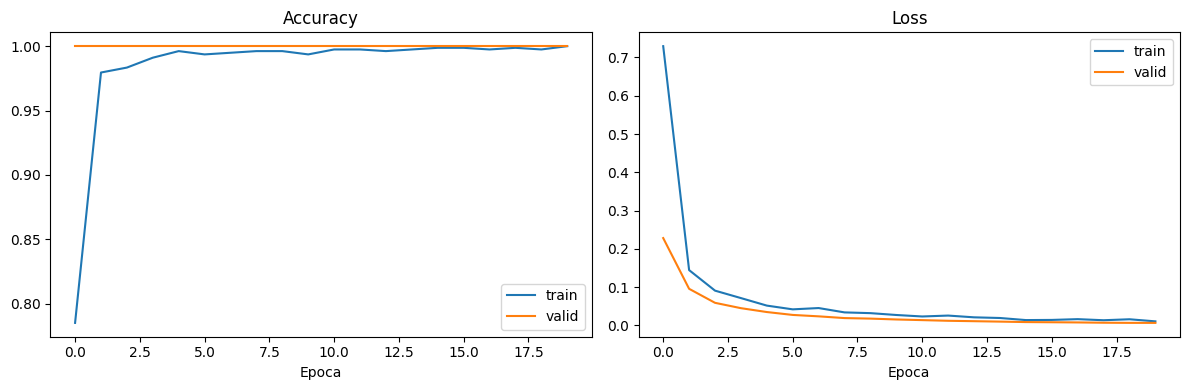

In [10]:
# Grafici di training: utili per rilevare underfitting/overfitting.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history.get("accuracy", []), label="train")
axes[0].plot(history.history.get("val_accuracy", []), label="valid")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoca")
axes[0].legend()

axes[1].plot(history.history.get("loss", []), label="train")
axes[1].plot(history.history.get("val_loss", []), label="valid")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoca")
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. Calibrazione e quantizzazione post-training per IMX500

MCT stima i parametri di quantizzazione usando batch di immagini rappresentative del training set. In questa versione il generatore scorre fino a `NUM_CALIBRATION_BATCHES` batch del dataset di calibrazione, che non contiene data augmentation casuale. La configurazione target resta quella IMX500 v1 usata dal tutorial Sony.

In [11]:
from typing import Iterator
import model_compression_toolkit as mct
from model_compression_toolkit.core import QuantizationErrorMethod


def representative_dataset() -> Iterator[np.ndarray]:
    """Genera batch di immagini pre-processate per la calibrazione PTQ."""
    for images, _labels in train_calibration_ds.take(NUM_CALIBRATION_BATCHES):
        yield images.numpy()


representative_dataset_gen = representative_dataset

tpc = mct.get_target_platform_capabilities(
    "tensorflow",
    "imx500",
    target_platform_version="v1",
)

quantization_config = mct.core.QuantizationConfig(
    activation_error_method=QuantizationErrorMethod.MSE,
    weights_error_method=QuantizationErrorMethod.MSE,
    weights_bias_correction=True,
    shift_negative_activation_correction=True,
    z_threshold=16,
)
ptq_config = mct.core.CoreConfig(quantization_config=quantization_config)

print("Batch di calibrazione disponibili:", min(NUM_CALIBRATION_BATCHES, int(np.ceil(train_count / BATCH_SIZE))))

Batch di calibrazione disponibili: 10


In [12]:
quantized_model, quantization_info = mct.ptq.keras_post_training_quantization(
    in_model=float_model,
    representative_data_gen=representative_dataset_gen,
    core_config=ptq_config,
    target_platform_capabilities=tpc,
)

mct.exporter.keras_export_model(
    model=quantized_model,
    save_model_path=str(MODEL_QUANTIZED),
)

if not MODEL_QUANTIZED.exists():
    raise FileNotFoundError(f"Il modello quantizzato non è stato creato: {MODEL_QUANTIZED}")

print("Modello quantizzato esportato in:", MODEL_QUANTIZED.resolve())

persist_artifacts_to_drive()

Statistics Collection: 10it [01:27,  8.80s/it]



Running quantization parameters search. This process might take some time, depending on the model size and the selected quantization methods.



Calculating quantization parameters: 100%|██████████| 105/105 [00:16<00:00,  6.44it/s]


Weights_memory: 2196160.0, Activation_memory: 1204224.0, Total_memory: 3400384.0, BOPS: 45502185472.0

Please run your accuracy evaluation on the exported quantized model to verify it's accuracy.
Checkout the FAQ and Troubleshooting pages for resolving common issues and improving the quantized model accuracy:
FAQ: https://github.com/sony/model_optimization/tree/main/FAQ.md
Quantization Troubleshooting: https://github.com/sony/model_optimization/tree/main/quantization_troubleshooting.md
Exporting Keras model with MCTQ custom quantizers to: models/birdgarden/mobilenetv2_birdgarden_quant.keras
Modello quantizzato esportato in: /content/models/birdgarden/mobilenetv2_birdgarden_quant.keras
Modelli copiati/aggiornati su Drive: /mnt/drive/MyDrive/Birdgarden/artifacts/models


## 11. Valutazione finale sul test set indipendente

Questa sezione usa `test/` solamente dopo il training e la quantizzazione. Se il test set è piccolo o alcune classi sono scarsamente rappresentate, le metriche possono essere instabili: considerare anche immagini nuove raccolte in condizioni simili all'uso reale.


=== Test — modello float ===
loss: 0.0021
accuracy: 1.0000

Report per classe:
                   precision    recall  f1-score   support

   ANDEAN SISKIN       1.00      1.00      1.00         5
AZARAS SPINETAIL       1.00      1.00      1.00         5
       AZURE JAY       1.00      1.00      1.00         5
     BANDED PITA       1.00      1.00      1.00         5
        BARN OWL       1.00      1.00      1.00         5

        accuracy                           1.00        25
       macro avg       1.00      1.00      1.00        25
    weighted avg       1.00      1.00      1.00        25

Matrice di confusione (righe=reale, colonne=predetta):
 [[5 0 0 0 0]
 [0 5 0 0 0]
 [0 0 5 0 0]
 [0 0 0 5 0]
 [0 0 0 0 5]]


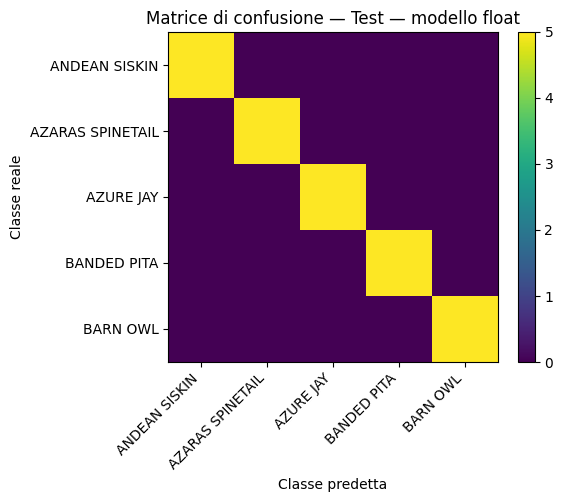


=== Test — modello quantizzato ===
loss: 0.0013
accuracy: 1.0000

Report per classe:
                   precision    recall  f1-score   support

   ANDEAN SISKIN       1.00      1.00      1.00         5
AZARAS SPINETAIL       1.00      1.00      1.00         5
       AZURE JAY       1.00      1.00      1.00         5
     BANDED PITA       1.00      1.00      1.00         5
        BARN OWL       1.00      1.00      1.00         5

        accuracy                           1.00        25
       macro avg       1.00      1.00      1.00        25
    weighted avg       1.00      1.00      1.00        25

Matrice di confusione (righe=reale, colonne=predetta):
 [[5 0 0 0 0]
 [0 5 0 0 0]
 [0 0 5 0 0]
 [0 0 0 5 0]
 [0 0 0 0 5]]


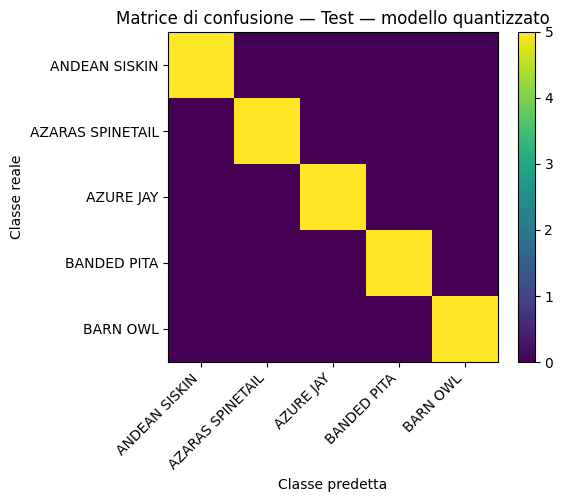

Risultati del test salvati in: /content/models/birdgarden/test_metrics.json


In [13]:
from sklearn.metrics import classification_report, confusion_matrix


def evaluate_classifier(model, dataset, split_name):
    """Valuta un classificatore e stampa metriche aggregate e per classe."""
    scalar_metrics = model.evaluate(dataset, verbose=0, return_dict=True)
    y_true = np.concatenate([labels.numpy().reshape(-1) for _images, labels in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    report_text = classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0,
    )
    matrix = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

    print(f"\n=== {split_name} ===")
    for metric_name, metric_value in scalar_metrics.items():
        print(f"{metric_name}: {float(metric_value):.4f}")
    print("\nReport per classe:\n", report_text)
    print("Matrice di confusione (righe=reale, colonne=predetta):\n", matrix)

    result = {
        "split": split_name,
        "metrics": {key: float(value) for key, value in scalar_metrics.items()},
        "classification_report": classification_report(
            y_true,
            y_pred,
            labels=list(range(num_classes)),
            target_names=class_names,
            zero_division=0,
            output_dict=True,
        ),
        "confusion_matrix": matrix.tolist(),
        "class_names": class_names,
        "number_of_examples": int(len(y_true)),
    }

    fig, ax = plt.subplots(figsize=(max(6, num_classes * 1.1), max(5, num_classes * 0.9)))
    image = ax.imshow(matrix, interpolation="nearest")
    ax.set_title(f"Matrice di confusione — {split_name}")
    ax.set_xlabel("Classe predetta")
    ax.set_ylabel("Classe reale")
    ax.set_xticks(range(num_classes), labels=class_names, rotation=45, ha="right")
    ax.set_yticks(range(num_classes), labels=class_names)
    fig.colorbar(image, ax=ax)
    plt.tight_layout()
    plt.show()
    return result


for class_name, count in counts_by_split["test"].items():
    if count < 5:
        print(f"ATTENZIONE: il test set contiene solo {count} immagini della classe '{class_name}'.")

float_test_results = evaluate_classifier(float_model, test_ds, "Test — modello float")
quantized_model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
quantized_test_results = evaluate_classifier(quantized_model, test_ds, "Test — modello quantizzato")

all_test_results = {
    "note": "Test set tenuto separato da training e validazione; non usare questi risultati per selezionare ripetutamente configurazioni senza predisporre un nuovo test indipendente.",
    "float_model": float_test_results,
    "quantized_model": quantized_test_results,
}
with TEST_METRICS_FILE.open("w", encoding="utf-8") as f:
    json.dump(all_test_results, f, ensure_ascii=False, indent=2)
print("Risultati del test salvati in:", TEST_METRICS_FILE.resolve())

## 12. Visualizzazione delle classificazioni

Le funzioni sono chiamate `predict_class` e `visualize_classification`: non si tratta di object detection. Il punteggio è quello in uscita dalla softmax e non è necessariamente una probabilità calibrata. Un punteggio sotto soglia viene segnalato senza arrestare il notebook.

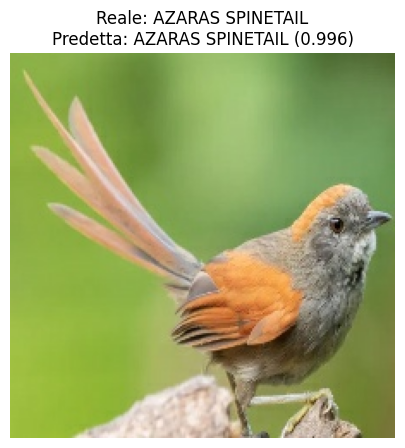

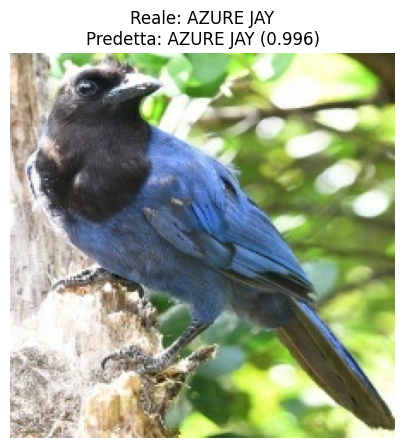

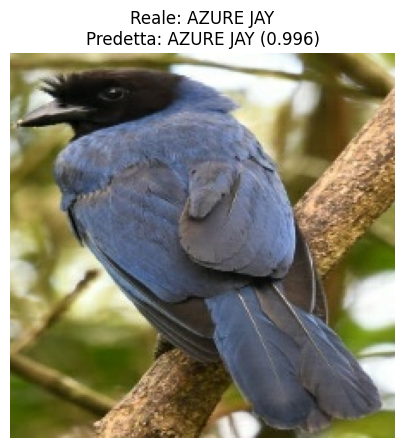

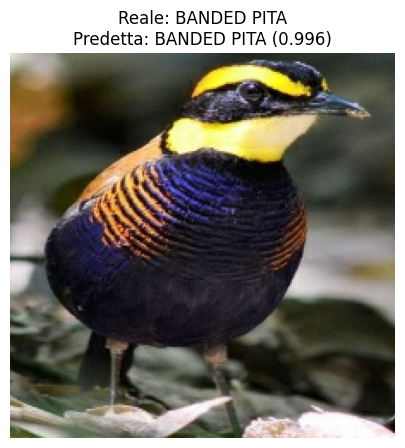

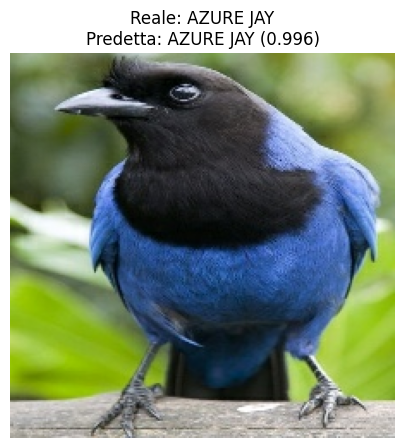

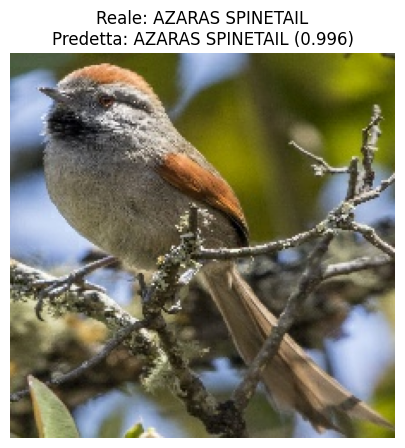

In [14]:
def predict_class(model, image):
    """Classifica una singola immagine RGB grezza (valori 0–255)."""
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, IMAGE_SHAPE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    batch = tf.expand_dims(image, axis=0)
    scores = model(batch, training=False).numpy()[0]
    top_index = int(np.argmax(scores))
    return class_names[top_index], float(scores[top_index]), scores


def visualize_classification(image, true_label_index, predicted_class, score):
    """Visualizza l'immagine con etichetta reale, predizione e score."""
    image_np = np.asarray(image).astype(np.uint8)
    true_label = class_names[int(true_label_index)]
    status = " — BASSA CONFIDENZA" if score < LOW_CONFIDENCE_THRESHOLD else ""
    plt.figure(figsize=(6, 5))
    plt.imshow(image_np)
    plt.title(
        f"Reale: {true_label}\nPredetta: {predicted_class} ({score:.3f}){status}"
    )
    plt.axis("off")
    plt.show()


preview_buffer = max(1, min(test_count, 1000))
for image, true_label_index in test_raw.shuffle(
    buffer_size=preview_buffer,
    seed=SEED,
    reshuffle_each_iteration=False,
).take(NUM_PREVIEW_IMAGES):
    predicted_class, score, all_scores = predict_class(quantized_model, image)
    if score < LOW_CONFIDENCE_THRESHOLD:
        print(
            f"Avviso: punteggio basso ({score:.3f}) per '{predicted_class}'. "
            "Controllare l'immagine o acquisire più esempi."
        )
    visualize_classification(image.numpy(), true_label_index.numpy(), predicted_class, score)

## 13. Conversione del modello quantizzato con IMX500 Converter

Il convertitore genera gli artefatti usati nel successivo processo di packaging per Raspberry Pi AI Camera. Il completamento di questa cella **non installa** da solo il modello sulla fotocamera: seguire poi la procedura Raspberry Pi/Sony appropriata alla versione in uso.

In [15]:
import tempfile
import uuid

if not MODEL_QUANTIZED.exists():
    raise FileNotFoundError(
        f"Modello quantizzato non trovato: {MODEL_QUANTIZED}. Esegui prima le celle di quantizzazione."
    )

# Definiamo un percorso di output temporaneo univoco per evitare che il convertitore rilevi una cartella esistente
temp_suffix = f"_temp_{uuid.uuid4().hex[:8]}"
TEMP_CONVERTED_DIR = CONVERTED_DIR.with_name(CONVERTED_DIR.name + temp_suffix)

if TEMP_CONVERTED_DIR.exists():
    shutil.rmtree(TEMP_CONVERTED_DIR)

converter_path = shutil.which("imxconv-tf")
if converter_path is None:
    raise FileNotFoundError(
        "Comando 'imxconv-tf' non trovato. Verifica che imx500-converter[tf] sia installato "
        "nell'ambiente Python attivo."
    )

# Eseguiamo la conversione puntando alla cartella temporanea (sicuramente non esistente)
command = [
    converter_path,
    "-i", str(MODEL_QUANTIZED),
    "-o", str(TEMP_CONVERTED_DIR),
]
print("Esecuzione:", " ".join(command))

try:
    result = subprocess.run(command, check=True, capture_output=True, text=True)
    print(result.stdout)
except subprocess.CalledProcessError as e:
    print("--- ERRORE DURANTE LA CONVERSIONE ---")
    print("STDOUT:")
    print(e.stdout)
    print("STDERR:")
    print(e.stderr)
    if TEMP_CONVERTED_DIR.exists():
        shutil.rmtree(TEMP_CONVERTED_DIR)
    raise e

# Se la conversione ha successo, spostiamo i file nella cartella di destinazione finale
if TEMP_CONVERTED_DIR.exists():
    if CONVERTED_DIR.exists():
        shutil.rmtree(CONVERTED_DIR)
    shutil.move(str(TEMP_CONVERTED_DIR), str(CONVERTED_DIR))

packer_file = CONVERTED_DIR / "packerOut.zip"
if not packer_file.is_file():
    print("File presenti nella directory di conversione:")
    if CONVERTED_DIR.exists():
        for path in sorted(CONVERTED_DIR.iterdir()):
            print(" -", path.name)
    raise FileNotFoundError(
        f"Il convertitore non ha prodotto il file atteso: {packer_file}. "
        "Controllare il log del convertitore e la documentazione Sony."
    )

print("Conversione completata. Artefatto principale:", packer_file.resolve())
print("File generati:")
for path in sorted(CONVERTED_DIR.iterdir()):
    print(f" - {path.name} ({path.stat().st_size:,} byte)")

persist_artifacts_to_drive()

Esecuzione: /usr/local/bin/imxconv-tf -i models/birdgarden/mobilenetv2_birdgarden_quant.keras -o converted/birdgarden_temp_16091c94
2026-10-18 18:19:16,556 INFO : Running version 3.16.1 [/usr/local/lib/python3.11/dist-packages/uni/common/logger.py:179]
2026-10-18 18:19:16,557 INFO : Converting models/birdgarden/mobilenetv2_birdgarden_quant.keras [/usr/local/lib/python3.11/dist-packages/uni/common/logger.py:179]
2026-10-18 18:19:20,983 INFO : NumExpr defaulting to 2 threads. [/usr/local/lib/python3.11/dist-packages/numexpr/utils.py:164]
2026-10-18 18:19:29,825 INFO : Wrote outputs to /tmp/tmph3zvqdwb/mobilenetv2_birdgarden_quant.uni-tensorflow.um.pb [/usr/local/lib/python3.11/dist-packages/uni/common/logger.py:179]
2026-10-18 18:19:29,853 INFO : Converted successfully [/usr/local/lib/python3.11/dist-packages/uni/common/logger.py:179]
2026-10-18 18:19:31,420 INFO : CODE: [START] Starting SDSPconv
2026-10-18 18:20:20,666 INFO : ConvFe conversion finished successfully
2026-10-18 18:20:25,7

## 14. Persistenza degli artefatti su Google Drive

In Colab il filesystem locale del runtime può essere eliminato al termine della sessione. Questa cella copia su Drive la cartella dei modelli e quella di conversione. Fuori da Colab, i file rimangono nelle cartelle locali `models/birdgarden/` e `converted/birdgarden/`; copiarli su una destinazione persistente prima di cancellare l'ambiente.

In [16]:
persist_artifacts_to_drive()

Modelli copiati/aggiornati su Drive: /mnt/drive/MyDrive/Birdgarden/artifacts/models
Artefatti di conversione copiati/aggiornati su Drive: /mnt/drive/MyDrive/Birdgarden/artifacts/converted


## 15. Checklist finale

Prima di considerare il modello pronto per Birdgarden:

- [ ] verificare che le cartelle `train`, `valid` e `test` contengano immagini rappresentative e non duplicate tra loro;
- [ ] esaminare `test_metrics.json`, in particolare precision, recall e matrice di confusione per ogni classe;
- [ ] verificare la classificazione su foto nuove, realizzate con la camera e con le condizioni luminose previste nell'applicazione;
- [ ] conservare insieme al modello `class_names.json`, `dataset_metadata.json` e `training_config.json`;
- [ ] completare il packaging/trasferimento del modello sulla Raspberry Pi AI Camera seguendo le istruzioni ufficiali aggiornate;
- [ ] se l'obiettivo è classificare un uccello dentro una scena più ampia, progettare una fase precedente di localizzazione/ritaglio: questo notebook da solo non esegue detection.

**Riferimenti:** [Raspberry Pi AI Camera — documentazione ufficiale](https://www.raspberrypi.com/documentation/accessories/ai-camera.html) · [Sony IMX500 Converter](https://developer.aitrios.sony-semicon.com/en/raspberrypi-ai-camera/documentation/imx500-converter) · [Sony Model Compression Toolkit](https://github.com/sony/model_optimization).

## Risoluzione dei problemi: errore `RecursionError` in `ml_dtypes` o `TypeError` in TensorFlow

Se durante `import tensorflow as tf` compare un errore ricorsivo in `numpy.core._dtype` / `ml_dtypes._finfo`, il runtime sta probabilmente usando versioni non compatibili, oppure il processo ha ancora in memoria NumPy caricato prima del downgrade. Per questa combinazione di TensorFlow e IMX500 Converter usa NumPy 1.26.4 e `ml-dtypes` 0.2.0; non basta installarli, bisogna riavviare il runtime dopo la modifica.

1. Esegui la cella **Installazione delle dipendenze**.
2. Se la cella interrompe l'esecuzione segnalando che l'ambiente è stato aggiornato, scegli **Runtime/Ambiente di esecuzione → Restart session/Riavvia sessione**.
3. Dopo il riavvio, esegui il notebook dall'inizio. La cella di installazione dovrebbe rilevare le versioni già corrette e non reinstallarle.

Riferimenti: [vincoli di TensorFlow 2.14.1](https://pypi.org/project/tensorflow/2.14.1/) · [specifiche di IMX500 Converter 3.16.1](https://developer.aitrios.sony-semicon.com/docs/raspberry-pi-ai-camera/imx500-converter?version=3.16.1).
